# Estado del arte: los modelos supervisores de pruebas de estrés, cópulas vine, crecimiento en riesgo y VAR bayesianos

**Pregunta:** Frente a la práctica publicada para agregar riesgos y medir el riesgo de modelo, ¿cuánto esconde una sola cifra de
capital de Banco Andino, y cuánto podría equivocarse el modelo de referencia antes de que su capital cambie?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los notebooks 01 a 03 de este tema (la agregación, la banda y sus cotas)
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook puedes:

- simular el agregado gaussiano de los cuatro riesgos de Banco Andino y leer su capital, la cifra única que las medidas
  publicadas de riesgo de modelo van a cuestionar;
- leer la práctica publicada sobre modelos supervisores de pruebas de estrés, generadores de escenarios, agregación de riesgos y
  riesgo de modelo, y decir qué implementa el caso y qué deja fuera;
- ejecutar el multiplicador de recargo y la medida relativa de Barrieu y Scandolo sobre los ocho modelos de la banda, y leer lo
  que dicen sobre la dispersión entre los modelos;
- ejecutar el peor caso de Glasserman y Xu dentro de un presupuesto de entropía sobre el agregado simulado, y decir qué tan
  rápido crece;
- comparar el caso con la práctica publicada en los números que se pueden medir en los documentos versionados.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un notebook nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del notebook que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el notebook e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importaciones, versiones y lector de los documentos versionados (tres carpetas bajo la raíz del repositorio)
import importlib.metadata as md
import json
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import model_risk
from riskvalidation.portfolio import portfolio as rv_port
from riskvalidation.validation import aggregation as agg_tests

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
DERIVED = Path("../../..").resolve() / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Este notebook lee el bloque de agregación de **C18** (Banco Andino), como los notebooks 01 a 03.

- **Propietario y licencia:** los documentos los escribe el flujo sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este notebook son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este notebook, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/baseline.json` (`outputs.aggregation`: marginales, banda, matriz de correlación y el bloque `model_risk` versionado con los resultados de Barrieu-Scandolo y Glasserman-Xu; y `outputs.backcast` para el ajuste fuera de tiempo de los satélites), `data/derived/C18/t-copula-baseline.json` (la referencia de Rosenberg y Schuermann) y `data/derived/C18/models-banco-andino.json` (`fit.aggregation.quantile_grid`).
- **Las marginales se reconstruyen desde las grillas de cuantiles versionadas, para un paso.** La medida de Glasserman-Xu necesita las pérdidas simuladas del agregado, que el documento no tiene, así que el paso 2 reconstruye las marginales del notebook 02 desde las grillas y simula el agregado gaussiano con la semilla del caso; los números versionados se imprimen al lado.

In [2]:
# El bloque de agregación base, la matriz de correlación, la banda y las grillas de cuantiles versionadas
baseline_doc = read_json("C18/baseline.json")
agg = baseline_doc["outputs"]["aggregation"]
grid = read_json("C18/models-banco-andino.json")["fit"]["aggregation"]["quantile_grid"]
R = np.array(agg["correlation"]["matrix"])
band = agg["band"]
marginals = agg["marginals"]
NAMES = {"lower-bound": "cota inferior", "simple-sum": "suma simple",
         "variance-covariance": "varianza-covarianza", "gaussian-copula": "cópula gaussiana (referencia)",
         "t-copula": "cópula t", "worst-case": "peor caso"}

## Método

### Paso 1: el capital que se cuestiona

El método propio del caso es la agregación de los notebooks 01 a 03: cuatro marginales, una matriz de correlación, una cópula y
una cifra de capital con una banda alrededor. Este paso lo ejecuta una vez más, como hizo el notebook 02: las cuatro funciones
de cuantiles se reconstruyen desde las grillas versionadas y `simulate_component_losses` genera un millón de pérdidas conjuntas
con la cópula gaussiana y la semilla del caso. Las dos celdas siguientes simulan, y luego leen el VaR, la pérdida esperada en
la cola y el capital económico del total con los estimadores del motor.

In [3]:
# Reconstruir las marginales desde las grillas versionadas y simular el agregado gaussiano de los cuatro riesgos
LEVEL = 0.999
probs = np.array(grid["probabilities"])
ppfs = [partial(np.interp, xp=probs, fp=np.array(q["quantiles"])) for q in grid["marginals"]]
joint = cop.simulate_component_losses(ppfs, R, "gaussian", None, 1_000_000, 42, 100_000)
total = joint.sum(axis=1)
print("escenarios simulados y riesgos", joint.shape)

escenarios simulados y riesgos (1000000, 4)


La celda siguiente lee el VaR y la pérdida esperada en la cola del total con los estimadores del motor y dibuja el histograma
del total en escala logarítmica con ambos marcados.

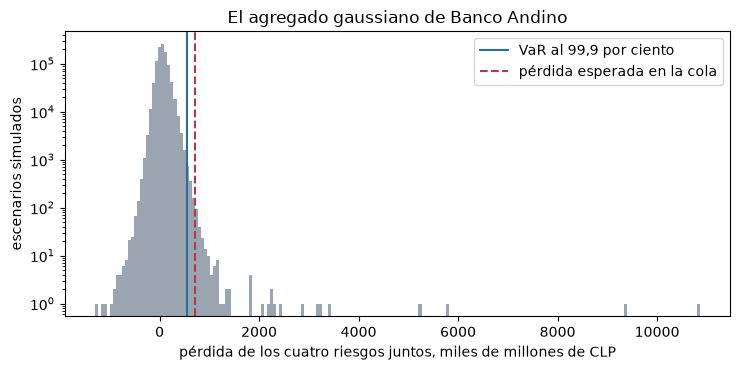

media, VaR y ES del total, millones de CLP
66898.7 558727.5 709402.5
capital económico, VaR menos pérdida esperada 491998.8


In [4]:
# El VaR y la pérdida esperada en la cola del total con los estimadores del motor, y el histograma del total
var_total = rv_port.var_from_sample(total, LEVEL)
es_total = rv_port.es_from_sample(total, LEVEL)
el_total = sum(m["el_clp_m"] for m in marginals)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(total / 1e3, bins=200, color="#9aa5b1", log=True)
ax.axvline(var_total / 1e3, color="#2a6f97", label="VaR al 99,9 por ciento")
ax.axvline(es_total / 1e3, color="#b23a48", linestyle="--", label="pérdida esperada en la cola")
ax.set_xlabel("pérdida de los cuatro riesgos juntos, miles de millones de CLP")
ax.set_ylabel("escenarios simulados")
ax.set_title("El agregado gaussiano de Banco Andino")
ax.legend()
fig.tight_layout()
plt.show()
print("media, VaR y ES del total, millones de CLP")
print(round(total.mean(), 1), round(var_total, 1), round(es_total, 1))
print("capital económico, VaR menos pérdida esperada", round(var_total - el_total, 1))

La media del total es 66.899 millones de pesos, que es su pérdida esperada, y el VaR de 99,9 por ciento queda muy a la derecha,
en 558.727 millones, con la pérdida esperada en la cola todavía más lejos: la cola es pesada, porque el riesgo operacional y el
de crédito tienen colas derechas largas. Restar la pérdida esperada da el capital económico de la cópula gaussiana, el modelo de
referencia de este notebook. Todo lo que sigue le hace la misma pregunta a este único número, cuánto de él es el modelo.

## Estado del arte

La investigación persistida (dossiers 05 y 06) declara la práctica en torno a cada parte del caso. La tabla la pone junto a lo que hace el caso, con la fuente y el estado de cada afirmación.

| Parte | La práctica publicada | En el caso y en el motor |
|---|---|---|
| **Modelos supervisores de pruebas de estrés** | La Reserva Federal publica ahora la documentación completa de sus modelos (otoño 2026, modelos de riesgo de crédito). La pérdida esperada corporativa es $PD \times LGD \times EAD$ por facilidad; el modelo de PD es un conjunto de 16 regresiones MCO de la PD de un proveedor sobre el diferencial BBB y su rezago de cuatro trimestres, estimadas 2006 a 2023; la LGD se estresa por el diferencial BBB, la EAD por un factor de equivalente de préstamo sobre datos del Shared National Credit; el PPNR tiene su propio conjunto de modelos 2026. | Cinco satélites MCO de tasas de castigo por tipo de préstamo sobre crecimiento del PIB y desempleo, ajustados 1985 a 2019 (notebook 04): una familia más simple y distinta. Los modelos de la Reserva Federal **no pueden replicarse a una tasa de pérdida publicada** desde el registro público, por lo cual el caso C19 sigue planificado (notebook 09). |
| **Abajo-arriba con restricciones** | El ejercicio de la EBA 2025 es una prueba de estrés abajo-arriba restringida: los bancos usan sus propios modelos con parámetros prescritos, con un balance estático y parámetros de referencia donde no existe un satélite adecuado (Nota Metodológica, párrafos 33 a 38 y 122 a 124). | Las reglas estáticas por párrafo se aplican y se prueban (notebook 05); el caso tiene un banco y ningún retador, así que abajo-arriba frente a arriba-abajo es una regla mostrada, no una comparación hecha (notebook 07). |
| **Generadores de escenarios** | VAR bayesianos con a priori de Minnesota (Litterman 1986; Banbura, Giannone y Reichlin 2010), VAR globales, crecimiento en riesgo con una densidad t asimétrica (Adrian, Boyarchenko y Giannone 2019) y un satélite de cuantiles en panel (Covas, Rump y Zakrajsek 2014). | El motor tiene el pronóstico condicional del VAR y el paso t asimétrico del crecimiento en riesgo (notebook 04); el paso de regresiones cuantílicas necesita `statsmodels`, ausente de este entorno; el BVAR de Minnesota y el satélite de cuantiles en panel están diferidos (ítem de backlog BL-078). |
| **Agregación de riesgos** | Rosenberg y Schuermann (2006): el riesgo total es más sensible a la mezcla de negocios que a las correlaciones entre riesgos, la elección de cópula tiene un efecto modesto, y la aproximación aditiva sobrestima el riesgo en cerca de 30 a 40 por ciento. El Joint Forum encontró los modelos de agregación "un trabajo en progreso" en los que los supervisores en general no confían (el comunicado de prensa del 21 de octubre de 2010, https://www.bis.org/press/p101021.htm, trae ambas frases). Las cópulas vine están disponibles sin conexión en `pyvinecopulib`. | La escalera desde la suma simple hasta el peor caso (notebooks 01 a 03), y la referencia de Rosenberg y Schuermann leída junto al resultado. El motor tiene cópulas gaussiana y t y las formas cerradas de Clayton; **las cópulas vine no están en el motor** (BL-078) y `pyvinecopulib` no está en este entorno. |
| **Cuantificación del riesgo de modelo** | Barrieu y Scandolo (2015) y Glasserman y Xu (2014), como arriba; las medidas cuantitativas de riesgo de modelo son información de sensibilidad, nunca una cifra de capital regulatorio. | Ambas están en el motor y corren en los pasos 1 y 2; el caso las rotula `information-not-capital`. |

Las dos primeras filas de la tabla conciernen a modelos que el caso no puede correr, los de la Reserva Federal y de la EBA, y la
tercera y la cuarta a herramientas que el motor tiene solo en parte; la última fila, el riesgo de modelo, se ejecuta en los dos
pasos siguientes, y la celda posterior mide lo que los documentos versionados permiten medir.

### Medida 1: el riesgo de modelo sobre el conjunto de modelos de agregación

La banda del notebook 03 es un **conjunto de modelos** para una cantidad (el capital): la regla de la raíz cuadrada, la cópula gaussiana, tres cópulas t y las dos cotas. Una sola cifra oculta la dispersión entre ellos, y la literatura tiene medidas de esa dispersión (Barrieu y Scandolo, 2015). Sea $\rho(X_0)$ la medida bajo el **modelo de referencia**, y $\overline\rho$ y $\underline\rho$ su mayor y menor valor sobre el conjunto $\mathcal L$. Entonces

$$\mathrm{AM} = \frac{\overline\rho}{\rho(X_0)} - 1, \qquad \mathrm{RM} = \frac{\overline\rho - \rho(X_0)}{\overline\rho - \underline\rho} \in [0, 1].$$

El **multiplicador de recargo** AM generaliza el multiplicador de Basilea: multiplicar el capital de referencia por $1 + \mathrm{AM}$ llega al peor caso del conjunto. La **medida relativa** RM dice dónde está la referencia entre el mejor y el peor caso: 0 en el peor, 1 en el mejor. En el caso la referencia es la cópula gaussiana y el conjunto son las ocho filas de la banda, como información de sensibilidad, **no capital**.

La celda siguiente llama a `barrieu_scandolo` sobre los ocho capitales de la banda con la cópula gaussiana como referencia y le
ofrece un índice de referencia fuera del conjunto.

In [5]:
# Multiplicador de recargo y medida relativa de Barrieu-Scandolo sobre las ocho filas de la banda
capitals = [row["capital_clp_m"] for row in band]
labels = [(row["method"], row["nu"]) for row in band]
reference = labels.index(("gaussian-copula", None))
measures = model_risk.barrieu_scandolo(capitals, reference)
committed_bs = agg["model_risk"]["barrieu_scandolo"]
print("capital de referencia, peor y mejor del conjunto")
print(round(measures.rho_x0, 1), round(measures.rho_max, 1), round(measures.rho_min, 1))
print("AM", round(measures.am, 6), "RM", round(measures.rm, 6))
print("AM y RM versionados", round(committed_bs["am"], 6), round(committed_bs["rm"], 6))
print("referencia por 1 + AM", round(measures.rho_x0 * (1 + measures.am), 1))
print("1 + AM y RM, porcentaje", round(1 + measures.am, 2), round(measures.rm * 100))
try:
    model_risk.barrieu_scandolo(capitals, len(capitals))
except ValueError:
    print("un índice de referencia fuera del conjunto es rechazado")

capital de referencia, peor y mejor del conjunto
491973.5 823331.5 118517.5
AM 0.673528 RM 0.470135
AM y RM versionados 0.673528 0.470135
referencia por 1 + AM 823331.5
1 + AM y RM, porcentaje 1.67 47
un índice de referencia fuera del conjunto es rechazado


La celda siguiente dibuja los ocho capitales como múltiplos de la referencia gaussiana, con el rango que daría el exceso
aditivo publicado sombreado.

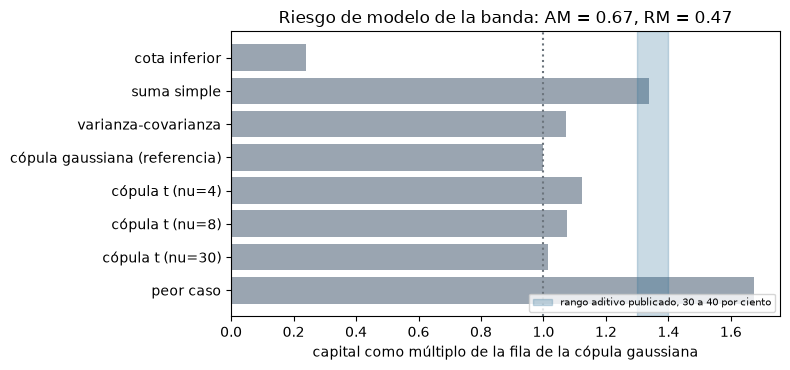

In [6]:
# La banda como múltiplo de la referencia gaussiana, con el rango aditivo publicado sombreado
multiple = [c / measures.rho_x0 for c in capitals]
names = [NAMES[m] + (f" (nu={nu:g})" if nu else "") for m, nu in labels]
published = "rango aditivo publicado, 30 a 40 por ciento"
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(names[::-1], multiple[::-1], color="#9aa5b1")
ax.axvspan(1.30, 1.40, color="#2a6f97", alpha=0.25, label=published)
ax.axvline(1.0, color="#6c757d", linestyle=":")
ax.set_xlabel("capital como múltiplo de la fila de la cópula gaussiana")
ax.set_title(f"Riesgo de modelo de la banda: AM = {measures.am:.2f}, RM = {measures.rm:.2f}")
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()

El conjunto de modelos es amplio. La referencia gaussiana es 491.974 millones de pesos y las ocho filas van desde 118.518
millones, la cota inferior, hasta 823.332 millones, el peor caso, una razón de 6,95. El multiplicador de recargo es 0,6735, de
modo que multiplicar la referencia por 1,67 alcanza el peor caso, y la medida relativa es 0,4701: la referencia queda a 47 por
ciento del camino desde el peor caso hacia el mejor. La franja sombreada es lo que Rosenberg y Schuermann esperarían para la
suma simple sobre una cifra diversificada, y la barra de la suma simple cae en ella, pero la dispersión del conjunto es mucho
más ancha que el rango del artículo.

### Medida 2: el peor caso dentro de un presupuesto de entropía

El conjunto de Barrieu y Scandolo es el conjunto de modelos que el analista escribió. Glasserman y Xu (2014) hacen otra pregunta: **¿cuán equivocado puede estar el modelo de referencia, de una manera medible, antes de que una cantidad cambie cuánto?** Se toma la ley base de una pérdida $V$ (aquí el agregado de la cópula gaussiana) y se consideran todas las leyes alternativas con razón de verosimilitud $m \ge 0$, $E[m] = 1$, cuya **entropía relativa** respecto de la base es a lo más un presupuesto $\eta$. La peor pérdida esperada es

$$\sup_{m \ge 0,\ E[m\log m] \le \eta} E[m\,V], \qquad m_\theta = \frac{e^{\theta V}}{E[e^{\theta V}]},$$

con $\theta > 0$ elegido de modo que la restricción de entropía se active: el peor caso **inclina** la muestra base hacia sus pérdidas grandes, de forma exponencial. Cuesta solo un reponderado de la simulación base. `glasserman_xu_worst_case(v, budget)` devuelve la inclinación $\theta$, la entropía alcanzada, la media base y la media del peor caso, y rechaza un presupuesto que la muestra no puede alcanzar (la entropía de una inclinación es a lo más $\log S$).

El caso usa el presupuesto $\eta = 0,05$ sobre el agregado gaussiano.

La celda siguiente ejecuta `glasserman_xu_worst_case` sobre el agregado simulado del paso 1 con presupuestos de 0,005 a 0,25,
imprime cuatro de ellos y el rechazo de uno inalcanzable.

In [7]:
# El peor caso de Glasserman-Xu dentro de un presupuesto de entropía: un barrido de presupuestos, cuatro
# impresos y un rechazo
budgets = np.linspace(0.005, 0.25, 25)
runs = [model_risk.glasserman_xu_worst_case(total, b) for b in budgets]
print("presupuesto, inclinación, entropía, base, peor caso, razón")
for budget in (0.01, 0.05, 0.1, 0.2):
    gx = model_risk.glasserman_xu_worst_case(total, budget)
    row = (budget, gx.theta, gx.relative_entropy, gx.baseline, gx.worst_case, gx.worst_case / gx.baseline)
    print("%5.2f %10.3e %7.4f %11.1f %11.1f %5.2f" % row)
committed_gx = agg["model_risk"]["glasserman_xu"]
print("versionado, presupuesto 0,05")
print(round(committed_gx["baseline_clp_m"], 1), round(committed_gx["worst_case_clp_m"], 1))
try:
    model_risk.glasserman_xu_worst_case(total[:50], 10.0)
except ValueError:
    print("un presupuesto que la muestra no alcanza es rechazado")

presupuesto, inclinación, entropía, base, peor caso, razón
 0.01  6.367e-07  0.0100     66898.7     88454.2  1.32
 0.05  7.878e-07  0.0500     66898.7    143206.7  2.14
 0.10  8.497e-07  0.1000     66898.7    204035.3  3.05
 0.20  9.114e-07  0.2000     66898.7    317194.7  4.74
versionado, presupuesto 0,05
66898.5 143201.8
un presupuesto que la muestra no alcanza es rechazado


La celda siguiente dibuja la peor pérdida esperada del barrido como múltiplo de la base, con el presupuesto del caso marcado.

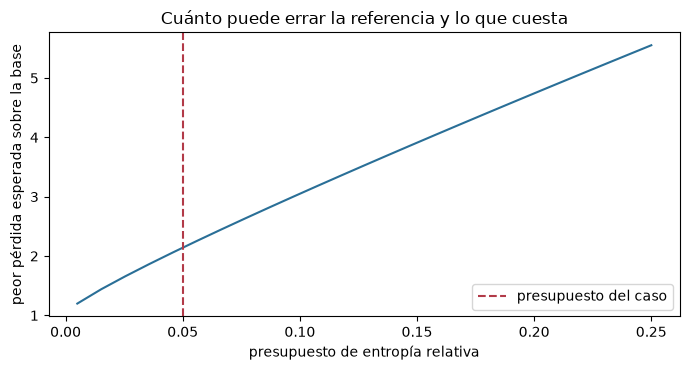

In [8]:
# La peor pérdida esperada sobre la base cuando crece el presupuesto de entropía
ratio = [r.worst_case / r.baseline for r in runs]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(budgets, ratio, color="#2a6f97")
ax.axvline(0.05, color="#b23a48", linestyle="--", label="presupuesto del caso")
ax.set_xlabel("presupuesto de entropía relativa")
ax.set_ylabel("peor pérdida esperada sobre la base")
ax.set_title("Cuánto puede errar la referencia y lo que cuesta")
ax.legend()
fig.tight_layout()
plt.show()

El presupuesto de entropía convierte una duda de modelado en un número. Sobre el agregado simulado, cuya media base es 66.899
millones de pesos, la peor pérdida esperada con un presupuesto de 0,01; 0,05; 0,10 y 0,20 es 88.454; 143.207; 204.035 y
317.195, que son 1,32; 2,14; 3,05 y 4,74 veces la base. Con el presupuesto del caso, 0,05, coincide con el bloque versionado,
143.202. La curva es convexa: el peor caso crece más rápido que el presupuesto porque el agregado tiene cola pesada, y cuanta
más cola tiene la base, más puede mover su media un presupuesto dado. Un presupuesto que la muestra no alcanza, sobre log S de
3,91, se rechaza.

### Medir el resto de la tabla

La celda siguiente lee de los documentos versionados aquello en que se puede medir cada fila restante de la tabla: el exceso
aditivo frente al rango publicado de Rosenberg y Schuermann, la dispersión de las filas de cópula sobre la gaussiana, la mezcla
de negocios del capital, y las razones de picos de la retroproyección de los satélites que representan la fila de modelos
supervisores.

In [9]:
# Medir en los documentos versionados aquello en que se puede medir cada fila restante de la tabla
gaussian = next(r["capital_clp_m"] for r in band if r["method"] == "gaussian-copula")
simple_sum = agg["headline"]["capital_clp_m"]
reference_doc = read_json("C18/t-copula-baseline.json")["outputs"]["rosenberg_schuermann"]
overestimate = agg_tests.rosenberg_schuermann_reference(simple_sum, gaussian)
print("exceso aditivo (motor)", round(overestimate.statistic, 4))
print("rango publicado", reference_doc["published_additive_overestimate"])
copula_rows = [r["capital_clp_m"] for r in band if r["method"] in ("gaussian-copula", "t-copula")]
print("dispersión de las filas de cópula sobre la gaussiana", round(max(copula_rows) / gaussian - 1, 4))
mix = {m["risk"]: round(m["ec_clp_m"] / simple_sum, 3) for m in marginals}
print("mezcla de negocios, parte de la suma simple", mix)
capitals_all = [r["capital_clp_m"] for r in band]
print("peor caso sobre cota inferior", round(max(capitals_all) / min(capitals_all), 2))
backcast = baseline_doc["outputs"]["backcast"]["per_loan_type"]
peaks = [round(b["metrics"]["peak_predicted"] / b["metrics"]["peak_realised"], 2) for b in backcast]
print("razones de picos de la retroproyección", peaks)

exceso aditivo (motor) 0.3376
rango publicado {'low': 0.3, 'high': 0.4}
dispersión de las filas de cópula sobre la gaussiana 0.1228
mezcla de negocios, parte de la suma simple {'credit': 0.396, 'market': 0.431, 'irrbb': 0.111, 'operational': 0.063}
peor caso sobre cota inferior 6.95
razones de picos de la retroproyección [4.55, 13.14, 252.13, 4.3, 2.09]


## Resultados

El caso queda dentro de la práctica publicada en los puntos donde se puede medir, y su distancia a ella se declara. El exceso
aditivo de 0,3376 está dentro del rango publicado de 30 a 40 por ciento, la cópula t con cuatro grados de libertad queda 12,3
por ciento sobre la gaussiana, un efecto de cópula mayor que el modesto del artículo, y las razones de picos de la
retroproyección, 2,09 a 252,13, dicen que la pérdida de crédito estresada se apoya en satélites que fallan su propia validación
(notebook 07).

**Respuesta:** una sola cifra de capital esconde mucho. La referencia gaussiana de 491.974 millones de pesos está a 47 por
ciento del camino desde el peor caso de 823.332 millones hasta el mejor de 118.518, el multiplicador de recargo es 0,6735 (el
peor caso es 1,67 veces la referencia), y un presupuesto de entropía de 0,05 sobre el agregado simulado levanta su pérdida
esperada de 66.899 a 143.207 millones, 2,14 veces, con 4,74 veces con un presupuesto de 0,20. Lo que le falta al caso se
declara: los modelos de la Reserva Federal no pueden replicarse hasta una tasa de pérdida publicada desde el registro público,
las cópulas vine y el BVAR de Minnesota no están en el motor, y el primer paso del crecimiento en riesgo necesita un paquete
que este entorno no tiene.

Lo que este notebook no muestra: las cifras de Glasserman y Xu son sobre un agregado simulado desde una grilla de 1.961 puntos
por marginal, que coincide con el bloque versionado hasta 0,01 por ciento y no hasta el dígito; la tabla del estado del arte es
la de la investigación, con sus puntos NO VERIFICADOS marcados, no una revisión de literatura nueva; y ningún número de él es
un resultado regulatorio.

## Resumen

- La práctica publicada tiene tres capas: modelos supervisores (Reserva Federal, EBA), generadores de escenarios (BVAR, GVAR, crecimiento en riesgo, cuantiles en panel) y agregación (cópulas, vines, la cautela del Joint Forum); el caso implementa una familia de satélites más simple, las reglas estáticas de la EBA, un VAR y la mecánica t asimétrica, y la escalera gaussiana, t y de peor caso.
- El riesgo de modelo sobre la banda se mide con el multiplicador de recargo y la medida relativa de Barrieu y Scandolo, que el motor recalcula exactamente desde los capitales versionados, y con el peor caso de Glasserman-Xu dentro de un presupuesto de entropía, que necesita el agregado simulado y lo inclina hacia sus pérdidas grandes.
- Ambas medidas son información de sensibilidad para el validador, rotuladas `information-not-capital`, y dicen lo que una sola cifra de capital oculta.
- Lo que el motor no tiene se declara, no se oculta: cópulas vine, el BVAR de Minnesota, el satélite de cuantiles en panel y el primer paso del crecimiento en riesgo (necesita `statsmodels`); los modelos de la Reserva Federal no pueden replicarse a una tasa de pérdida publicada desde el registro público.

**Qué probar a continuación.** Cambia el modelo de referencia del paso 1 a la cópula t con $\nu = 4$ y mira cómo se mueven el multiplicador de recargo y la medida relativa; luego sigue con el notebook 09, que convierte la banda en una afirmación y lee la preparación declarada del caso.

## Referencias

- Glasserman, P. y Xu, X. (2014), Robust risk measurement and model risk, Quantitative Finance 14(1). https://doi.org/10.1080/14697688.2013.822989
- Barrieu, P. y Scandolo, G. (2015), Assessing financial model risk, European Journal of Operational Research 242(2). https://doi.org/10.1016/j.ejor.2014.10.032
- Rosenberg, J. V. y Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Joint Forum (2010), Developments in modelling risk aggregation (avances en la modelación de la agregación de riesgos). https://www.bis.org/publ/joint25.pdf
- Banco de Pagos Internacionales (2010), comunicado de prensa del 21 de octubre de 2010 sobre el informe del Joint Forum Developments in modelling risk aggregation. https://www.bis.org/press/p101021.htm
- Board of Governors of the Federal Reserve System (2026), Supervisory Stress Test Model Documentation: Credit Risk Models, Fall 2026 (documentación de los modelos de crédito). https://www.federalreserve.gov/supervisionreg/files/fall-2026-credit-risk-models-description.pdf
- EBA (2025), 2025 EU-wide stress test, Methodological Note del 2025-01-20: el balance estático (párrafos 24, 33, 34 y 90 a 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- Adrian, T., Boyarchenko, N. y Giannone, D. (2019), Vulnerable growth, American Economic Review 109(4). https://doi.org/10.1257/aer.20161923
- Litterman, R. B. (1986), Forecasting with Bayesian vector autoregressions: five years of experience, Journal of Business and Economic Statistics 4(1). https://doi.org/10.1080/07350015.1986.10509491
- Banbura, M., Giannone, D. y Reichlin, L. (2010), Large Bayesian vector auto regressions, Journal of Applied Econometrics 25(1). https://doi.org/10.1002/jae.1137
- Covas, F., Rump, B. y Zakrajsek, E. (2014), el satélite de cuantiles en panel, y Pesaran, Schuermann y Weiner (2004), el VAR global, como los resume el dossier 05, H.2 (sin enlace: no se leyeron en la base de investigación de este repositorio).
- Este repositorio: `docs/contracts/engine/aggregation-api.md` (las funciones de riesgo de modelo).